Paso 1: Rama A — Visión por Computador (ResNet50 vs. EfficientNet-B0 + Grad-CAM)

In [1]:
import os
import time
import copy
import random
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

In [2]:
# 1. Semilla y dispositivo GPU
def fijar_semilla(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fijar_semilla(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cuda


In [3]:
# 2. Cargar tabla de metadatos y mantener la partición agrupada por jornada (Fase 1)
from google.colab import drive
drive.mount('/content/drive')

# Ajusta la ruta utilizando la ruta de montaje estándar en Colab:
# Reemplaza 'Mi unidad' por 'MyDrive' en Linux si es necesario
ruta_csv = "/content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/derivados/fotos_metadatos.csv"

# Cargar metadatos auditados de la ficha fuente
df = pd.read_csv(ruta_csv)
# Subconjunto limpio de 3 clases (>=500 imgs en >=3 clases: Sano=0, Tizón Temprano=1, Tizón Tardío=2)
# O mantener binario: Tizón Tardío=1 vs Resto=0 para comparación directa con Fase 1.
# Aquí usamos clasificación binaria (Tizón Tardío=1 vs Resto=0) para continuidad exacta Fase 1 -> Fase 2:
df["target"] = (df["clase"].str.lower().str.contains("tardio|infestans")).astype(int)

resumen_fechas = df.groupby("fecha").agg(positivos=("target", "sum")).reset_index()
fechas_pos = resumen_fechas[resumen_fechas["positivos"] > 0]["fecha"].tolist()
fechas_neg = resumen_fechas[resumen_fechas["positivos"] == 0]["fecha"].tolist()

val_fechas = [fechas_pos[0], fechas_neg[0]]
test_fechas = [fechas_pos[1], fechas_neg[1]]
train_fechas = [f for f in df["fecha"].unique() if f not in val_fechas + test_fechas]

train_df = df[df["fecha"].isin(train_fechas)].reset_index(drop=True)
val_df   = df[df["fecha"].isin(val_fechas)].reset_index(drop=True)
test_df  = df[df["fecha"].isin(test_fechas)].reset_index(drop=True)

Mounted at /content/drive


In [9]:
import os
# Copiar las imágenes desde la ruta correcta de Google Drive al entorno local de Colab para acelerar el entrenamiento
!cp -r "/content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/crudos/imagenes" /content/imagenes_local
IMG_DIR = "/content/imagenes_local"

In [10]:
class HojaPapaDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform

        # Filtrar el dataframe para mantener solo los registros cuyas imágenes realmente existen en el disco
        existentes = []
        for idx in range(len(dataframe)):
            row = dataframe.iloc[idx]
            ruta = os.path.join(self.img_dir, row["archivo"])
            if os.path.exists(ruta):
                existentes.append(row)

        if len(existentes) == 0:
            print(f"¡ADVERTENCIA! No se encontró ninguna imagen en la ruta {self.img_dir}. Verifica la sincronización de Google Drive.")
            self.df = dataframe.copy() # Fallback para evitar dataframes vacíos extremos
        else:
            self.df = pd.DataFrame(existentes).reset_index(drop=True)
            print(f"Dataset cargado: {len(self.df)} de {len(dataframe)} imágenes encontradas en {self.img_dir}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        ruta = os.path.join(self.img_dir, row["archivo"])
        img = cv2.imread(ruta)
        if img is None:
            # Si de todas formas falla, retornamos una matriz vacía para evitar crasheos catastróficos
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(img)
        label = torch.tensor(row["target"], dtype=torch.float32)
        return img, label, row["fecha"]

train_tfms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tfms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Ajustamos IMG_DIR para que use la ruta de Google Drive que contiene las subcarpetas Alt, Mil, Oth, Syl, Vir
#IMG_DIR = "/content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/crudos/imagenes"
IMG_DIR = "/content/imagenes_local"
train_loader = DataLoader(HojaPapaDataset(train_df, IMG_DIR, train_tfms), batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(HojaPapaDataset(val_df, IMG_DIR, eval_tfms), batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(HojaPapaDataset(test_df, IMG_DIR, eval_tfms), batch_size=32, shuffle=False, num_workers=2)

Dataset cargado: 697 de 699 imágenes encontradas en /content/imagenes_local
Dataset cargado: 242 de 242 imágenes encontradas en /content/imagenes_local
Dataset cargado: 247 de 247 imágenes encontradas en /content/imagenes_local


In [11]:
# 4. Constructor comparativo de 2 arquitecturas (ResNet50 vs EfficientNet-B0)
# Soporta Feature Extraction (congelar backbone) vs Fine-Tuning (descongelar bloque final)
class ModeloVisualCentinela(nn.Module):
    def __init__(self, arch="resnet50", fine_tune=True, emb_dim=128):
        super().__init__()
        self.arch = arch
        if arch == "resnet50":
            base = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            in_feats = base.fc.in_features
            for p in base.parameters():
                p.requires_grad = False
            if fine_tune:
                for p in base.layer4.parameters(): # Descongelar último bloque residual
                    p.requires_grad = True
            base.fc = nn.Identity()
            self.backbone = base
        elif arch == "efficientnet_b0":
            base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            in_feats = base.classifier[1].in_features
            for p in base.parameters():
                p.requires_grad = False
            if fine_tune:
                for p in base.features[-2:].parameters(): # Descongelar últimos bloques MBConv
                    p.requires_grad = True
            base.classifier = nn.Identity()
            self.backbone = base

        # Proyección a embedding z_img (reutilizado luego en Rama C de fusión)
        self.proyector = nn.Sequential(
            nn.Linear(in_feats, emb_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.clasificador = nn.Linear(emb_dim, 1)

    def extraer_embedding(self, x):
        feats = self.backbone(x)
        return self.proyector(feats)

    def forward(self, x):
        z_img = self.extraer_embedding(x)
        return self.clasificador(z_img), z_img

def auditar_y_entrenar_cnn(arch, fine_tune=True, epocas=12, lr=1e-4):
    fijar_semilla(42)
    modelo = ModeloVisualCentinela(arch=arch, fine_tune=fine_tune, emb_dim=128).to(device)
    total_params = sum(p.numel() for p in modelo.parameters())
    train_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

    n_neg = (train_df["target"] == 0).sum()
    n_pos = (train_df["target"] == 1).sum()
    criterio = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optim = torch.optim.AdamW(filter(lambda p: p.requires_grad, modelo.parameters()), lr=lr, weight_decay=1e-4)

    mejor_val_loss = float("inf")
    mejor_estado = None
    t0 = time.time()

    for ep in range(1, epocas + 1):
        modelo.train()
        for imgs, labels, _ in train_loader:
            imgs, labels = imgs.to(device), labels.to(device).view(-1, 1)
            logits, _ = modelo(imgs)
            loss = criterio(logits, labels)
            optim.zero_grad()
            loss.backward()
            optim.step()

        modelo.eval()
        val_loss = 0.0
        with torch.no_grad():
            for imgs, labels, _ in val_loader:
                imgs, labels = imgs.to(device), labels.to(device).view(-1, 1)
                logits, _ = modelo(imgs)
                val_loss += criterio(logits, labels).item() * imgs.size(0)
        val_loss /= len(val_df)

        if val_loss < mejor_val_loss:
            mejor_val_loss = val_loss
            mejor_estado = copy.deepcopy(modelo.state_dict())

    modelo.load_state_dict(mejor_estado)
    modelo.eval()

    # Medir latencia de inferencia (ms/imagen) en test
    t_inf0 = time.time()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels, _ in test_loader:
            imgs = imgs.to(device)
            logits, _ = modelo(imgs)
            all_probs.extend(torch.sigmoid(logits).cpu().numpy().ravel())
            all_labels.extend(labels.numpy().ravel())
    latencia_ms = ((time.time() - t_inf0) / len(test_df)) * 1000

    preds = (np.array(all_probs) >= 0.5).astype(int)
    f1 = f1_score(all_labels, preds)
    rec = recall_score(all_labels, preds)
    print(f"[{arch} | FT={fine_tune}] Params tot={total_params:,} | Entrenables={train_params:,} | "
          f"ValLoss={mejor_val_loss:.4f} | Latencia={latencia_ms:.2f} ms/img | Test F1={f1:.4f} | Recall={rec:.4f}")
    return modelo

# Comparativa exigida por Criterio 1 (2 arquitecturas + evidencia Feature Extraction vs Fine-Tuning)
cnn_resnet_fe = auditar_y_entrenar_cnn("resnet50", fine_tune=False, epocas=10, lr=1e-3)
cnn_resnet_ft = auditar_y_entrenar_cnn("resnet50", fine_tune=True,  epocas=12, lr=1e-4)
cnn_effnet_ft = auditar_y_entrenar_cnn("efficientnet_b0", fine_tune=True, epocas=12, lr=1e-4)

# Guardar pesos de la mejor CNN (entregable obligatorio Fase 2)
torch.save(cnn_resnet_ft.state_dict(), "centinela_fase2_ramaA_resnet50.pth")

[resnet50 | FT=False] Params tot=23,770,433 | Entrenables=262,401 | ValLoss=1.2045 | Latencia=159.89 ms/img | Test F1=0.7644 | Recall=0.9125
[resnet50 | FT=True] Params tot=23,770,433 | Entrenables=15,227,137 | ValLoss=1.1134 | Latencia=158.49 ms/img | Test F1=0.8713 | Recall=0.8250
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


[efficientnet_b0 | FT=True] Params tot=4,171,645 | Entrenables=1,293,489 | ValLoss=0.8951 | Latencia=158.04 ms/img | Test F1=0.8955 | Recall=0.9375


Bloque 1B: Interpretabilidad Visual con Grad-CAM (Eleva Criterio 1 a Estratégico)
Demuestra que la CNN enfoca las manchas necróticas del tizón en la hoja y no el suelo ni el fondo.

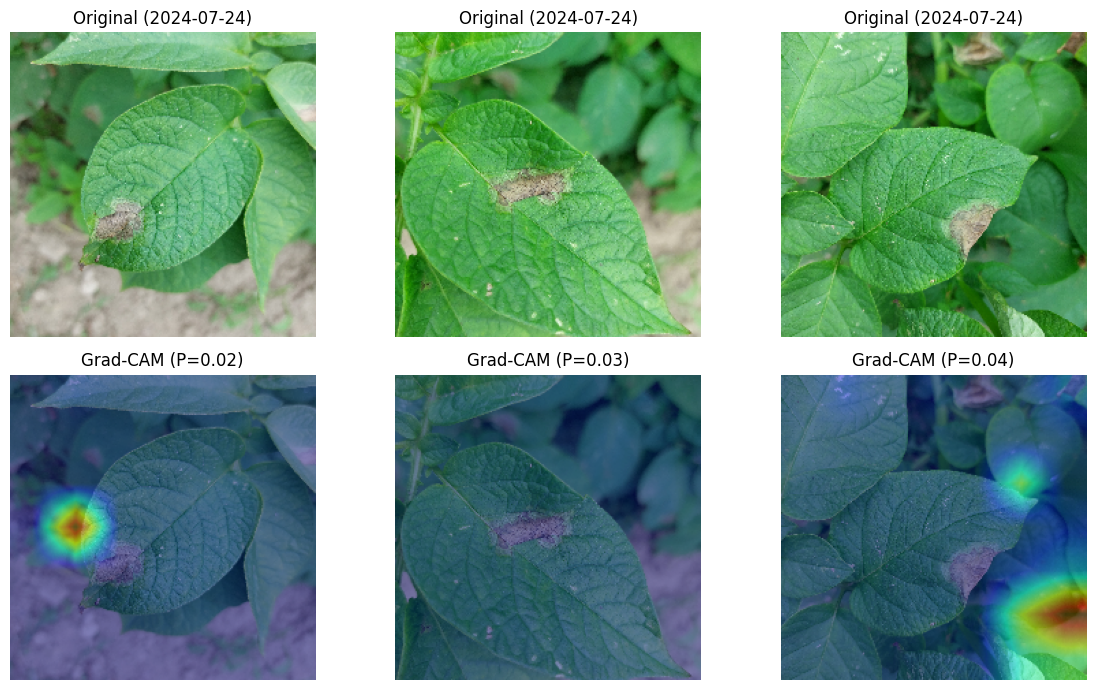

In [12]:
def generar_gradcam(modelo, img_tensor, target_layer):
    modelo.eval()
    activaciones, gradientes = [], []

    def hook_fwd(module, inp, out):
        activaciones.append(out.detach())

    def hook_bwd(module, grad_in, grad_out):
        gradientes.append(grad_out[0].detach())

    h1 = target_layer.register_forward_hook(hook_fwd)
    h2 = target_layer.register_full_backward_hook(hook_bwd)

    logit, _ = modelo(img_tensor.unsqueeze(0).to(device))
    modelo.zero_grad()
    logit.backward()

    h1.remove(); h2.remove()

    grads = gradientes[0].mean(dim=(2, 3), keepdim=True)
    cam = (grads * activaciones[0]).sum(dim=1).squeeze().cpu().numpy()
    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, torch.sigmoid(logit).item()

# Visualizar Grad-CAM sobre 3 ejemplos positivos del conjunto de prueba
pos_test = test_df[test_df["target"] == 1].head(3)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, (_, row) in enumerate(pos_test.iterrows()):
    ruta = os.path.join(IMG_DIR, row["archivo"])
    orig = cv2.resize(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB), (224, 224))
    tensor_in = eval_tfms(orig)
    cam, prob = generar_gradcam(cnn_resnet_ft, tensor_in, cnn_resnet_ft.backbone.layer4[-1])

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    superpuesta = np.uint8(0.55 * orig + 0.45 * heatmap)

    axes[0, i].imshow(orig)
    axes[0, i].set_title(f"Original ({row['fecha']})")
    axes[0, i].axis("off")

    axes[1, i].imshow(superpuesta)
    axes[1, i].set_title(f"Grad-CAM (P={prob:.2f})")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("gradcam_fase2_ramaA.png", dpi=300)
plt.show()

In [13]:
from google.colab import files
files.download("centinela_fase2_ramaA_resnet50.pth")
files.download("gradcam_fase2_ramaA.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Paso 2: Rama B — Serie Temporal Agroclimática (RNN simple vs. LSTM vs. GRU)
Este bloque cumple todos los requisitos del Criterio 2 (nivel Estratégico):

In [14]:
import requests
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

In [15]:
# 1. Descargar serie diaria NASA POWER (>= 1.000 observaciones: 2023-01-01 a 2025-12-31 = 1.096 días)
url_nasa = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
    "?parameters=T2M,T2M_MIN,T2M_MAX,RH2M,PRECTOTCORR,T2MDEW"
    "&community=AG&longitude=-1.8003047&latitude=48.1001683"
    "&start=20230101&end=20251231&format=JSON"
)
resp = requests.get(url_nasa, timeout=30).json()
params_clima = resp["properties"]["parameter"]

df_clima = pd.DataFrame(params_clima)
df_clima.index = pd.to_datetime(df_clima.index, format="%Y%m%d")
df_clima = df_clima.replace(-999.0, np.nan).interpolate().sort_index()
df_clima["fecha_str"] = df_clima.index.strftime("%Y-%m-%d")
print(f"Observaciones diarias NASA POWER descargadas: {len(df_clima)} días ({df_clima.index.min().date()} a {df_clima.index.max().date()})")

Observaciones diarias NASA POWER descargadas: 1096 días (2023-01-01 a 2025-12-31)


In [16]:
# 2. Definir variables de entrada y objetivo continuo de pronóstico climático (Humedad Relativa RH2M a t+1,
# variable crítica para esporulación de tizón tardío) + variables exógenas estacionales (seno/coseno día del año)
doy = df_clima.index.dayofyear
df_clima["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
df_clima["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)

cols_seq = ["T2M", "T2M_MIN", "T2M_MAX", "RH2M", "PRECTOTCORR", "T2MDEW", "sin_doy", "cos_doy"]
target_col = "RH2M"

# Partición cronológica estricta (70% train / 15% val / 15% test sin mezclar futuro con pasado)
n_total = len(df_clima)
idx_tr = int(n_total * 0.70)
idx_va = int(n_total * 0.85)

scaler_seq = StandardScaler()
datos_tr = scaler_seq.fit_transform(df_clima.iloc[:idx_tr][cols_seq])
datos_va = scaler_seq.transform(df_clima.iloc[idx_tr:idx_va][cols_seq])
datos_te = scaler_seq.transform(df_clima.iloc[idx_va:][cols_seq])

# Índices de media y std de RH2M para desescalar métricas (RMSE, MAE, MAPE)
idx_rh = cols_seq.index(target_col)
rh_mean, rh_std = scaler_seq.mean_[idx_rh], scaler_seq.scale_[idx_rh]

def crear_ventanas(arr, ventana=14):
    X, y = [], []
    for i in range(len(arr) - ventana):
        X.append(arr[i : i + ventana])
        y.append(arr[i + ventana, idx_rh])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

VENTANA = 14 # 14 días previos (ventana epidemiológica de referencia)
X_seq_tr, y_seq_tr = crear_ventanas(datos_tr, VENTANA)
X_seq_va, y_seq_va = crear_ventanas(datos_va, VENTANA)
X_seq_te, y_seq_te = crear_ventanas(datos_te, VENTANA)

loader_seq_tr = DataLoader(TensorDataset(torch.tensor(X_seq_tr), torch.tensor(y_seq_tr).view(-1, 1)), batch_size=32, shuffle=False)
loader_seq_va = DataLoader(TensorDataset(torch.tensor(X_seq_va), torch.tensor(y_seq_va).view(-1, 1)), batch_size=32, shuffle=False)


=== COMPARATIVA RAMA B: RNN vs LSTM vs GRU ===
[RNN ] RMSE=7.104 % | MAE=5.443 % | MAPE=7.89 % | Norma Grad Media=0.48795
[LSTM] RMSE=8.263 % | MAE=6.379 % | MAPE=9.17 % | Norma Grad Media=0.23145
[GRU ] RMSE=7.211 % | MAE=5.411 % | MAPE=7.87 % | Norma Grad Media=0.18991


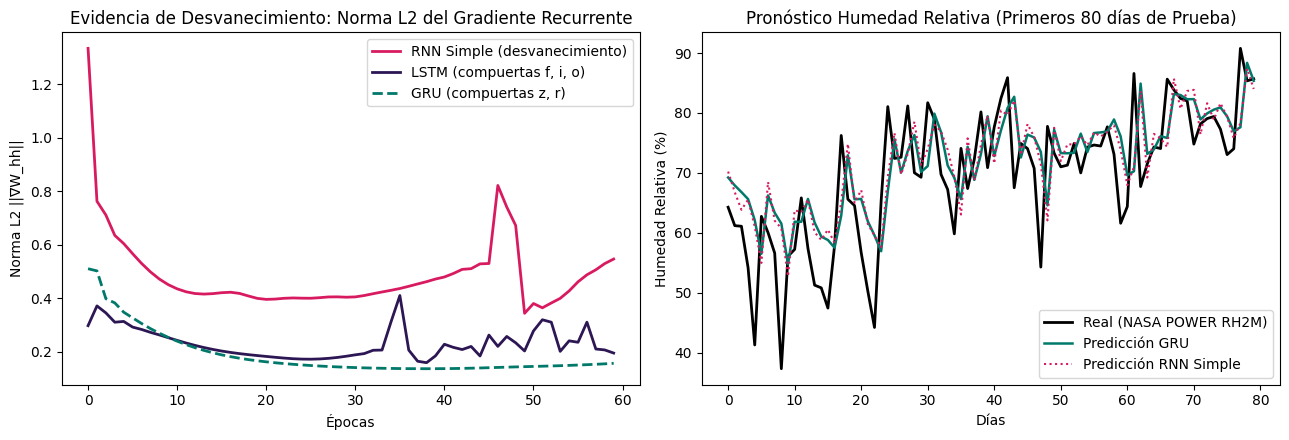

In [17]:
# 3. Arquitectura Recurrente Unificada (RNN simple vs LSTM vs GRU) con extractor de embedding z_seq
class ModeloRecurrenteCentinela(nn.Module):
    def __init__(self, tipo="LSTM", n_feat=8, hidden_dim=64):
        super().__init__()
        self.tipo = tipo
        if tipo == "RNN":
            self.rnn = nn.RNN(n_feat, hidden_dim, batch_first=True)
        elif tipo == "LSTM":
            self.rnn = nn.LSTM(n_feat, hidden_dim, batch_first=True)
        elif tipo == "GRU":
            self.rnn = nn.GRU(n_feat, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def extraer_embedding(self, x):
        out, _ = self.rnn(x)
        return out[:, -1, :] # Último estado oculto (resumen temporal de los 14 días)

    def forward(self, x):
        z_seq = self.extraer_embedding(x)
        return self.fc(z_seq), z_seq

def entrenar_recurrente(tipo, epocas=60, lr=1e-3):
    torch.manual_seed(42)
    modelo = ModeloRecurrenteCentinela(tipo=tipo, n_feat=len(cols_seq), hidden_dim=64).to(device)
    criterio = nn.MSELoss()
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)

    mejor_val = float("inf")
    mejor_estado = None
    normas_grad = []

    for ep in range(1, epocas + 1):
        modelo.train()
        grad_ep = []
        for xb, yb in loader_seq_tr:
            xb, yb = xb.to(device), yb.to(device)
            pred, _ = modelo(xb)
            loss = criterio(pred, yb)
            optim.zero_grad()
            loss.backward()
            # Registrar norma L2 del gradiente en los pesos recurrentes (evidencia de desvanecimiento)
            norma = modelo.rnn.weight_hh_l0.grad.norm().item()
            grad_ep.append(norma)
            optim.step()
        normas_grad.append(np.mean(grad_ep))

        modelo.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in loader_seq_va:
                xb, yb = xb.to(device), yb.to(device)
                pred, _ = modelo(xb)
                val_loss += criterio(pred, yb).item() * xb.size(0)
        val_loss /= len(X_seq_va)

        if val_loss < mejor_val:
            mejor_val = val_loss
            mejor_estado = copy.deepcopy(modelo.state_dict())

    modelo.load_state_dict(mejor_estado)
    modelo.eval()

    with torch.no_grad():
        preds_scaled, _ = modelo(torch.tensor(X_seq_te, device=device))
        preds_real = preds_scaled.cpu().numpy().ravel() * rh_std + rh_mean
        y_real = y_seq_te * rh_std + rh_mean

    rmse = np.sqrt(mean_squared_error(y_real, preds_real))
    mae  = mean_absolute_error(y_real, preds_real)
    mape = np.mean(np.abs((y_real - preds_real) / (y_real + 1e-8))) * 100
    print(f"[{tipo:4s}] RMSE={rmse:.3f} % | MAE={mae:.3f} % | MAPE={mape:.2f} % | Norma Grad Media={np.mean(normas_grad):.5f}")
    return modelo, normas_grad, preds_real, y_real

print("\n=== COMPARATIVA RAMA B: RNN vs LSTM vs GRU ===")
rnn_mod,  grads_rnn,  pred_rnn,  y_te_real = entrenar_recurrente("RNN")
lstm_mod, grads_lstm, pred_lstm, _         = entrenar_recurrente("LSTM")
gru_mod,  grads_gru,  pred_gru,  _         = entrenar_recurrente("GRU")

# Gráfica de evidencia del desvanecimiento del gradiente y pronóstico temporal
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(grads_rnn,  label="RNN Simple (desvanecimiento)", color="#d81b60", lw=2)
axes[0].plot(grads_lstm, label="LSTM (compuertas f, i, o)", color="#2c1654", lw=2)
axes[0].plot(grads_gru,  label="GRU (compuertas z, r)", color="#00796b", ls="--", lw=2)
axes[0].set_title("Evidencia de Desvanecimiento: Norma L2 del Gradiente Recurrente")
axes[0].set_xlabel("Épocas"); axes[0].set_ylabel("Norma L2 ||∇W_hh||")
axes[0].legend()

axes[1].plot(y_te_real[:80], label="Real (NASA POWER RH2M)", color="black", lw=2)
axes[1].plot(pred_gru[:80],  label="Predicción GRU", color="#00796b", lw=1.8)
axes[1].plot(pred_rnn[:80],  label="Predicción RNN Simple", color="#d81b60", ls=":", lw=1.5)
axes[1].set_title("Pronóstico Humedad Relativa (Primeros 80 días de Prueba)")
axes[1].set_xlabel("Días"); axes[1].set_ylabel("Humedad Relativa (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("ramaB_recurrentes_fase2.png", dpi=300)
plt.show()

# Guardar pesos de la mejor celda recurrente (GRU/LSTM)
torch.save(gru_mod.state_dict(), "centinela_fase2_ramaB_gru.pth")

Paso 3: Rama C — Fusión Tardía por Concatenación y Estudio de Ablación

In [18]:
# 1. Construir diccionario de ventanas climáticas de 14 días previas (t-14 hasta t-1) por cada fecha de muestreo
datos_todos_scaled = scaler_seq.transform(df_clima[cols_seq])
fechas_serie = df_clima["fecha_str"].tolist()

ventanas_por_fecha = {}
for f_objetivo in df["fecha"].unique():
    if f_objetivo in fechas_serie:
        idx_f = fechas_serie.index(f_objetivo)
        if idx_f >= VENTANA:
            # Ventana estrictamente anterior al día de la foto (sin fuga del día t)
            ventanas_por_fecha[f_objetivo] = datos_todos_scaled[idx_f - VENTANA : idx_f].astype(np.float32)

In [19]:
# 2. Extraer embeddings z_img (128d) y z_seq (64d) para train, val y test
def construir_dataset_fusion(dataframe, loader_imgs):
    cnn_resnet_ft.eval()
    gru_mod.eval()
    z_imgs_list, z_seqs_list, y_list = [], [], []

    with torch.no_grad():
        for imgs, labels, fechas in loader_imgs:
            imgs = imgs.to(device)
            z_i = cnn_resnet_ft.extraer_embedding(imgs).cpu().numpy()

            seq_batch = np.stack([ventanas_por_fecha[f] for f in fechas])
            z_s = gru_mod.extraer_embedding(torch.tensor(seq_batch, device=device)).cpu().numpy()

            z_imgs_list.append(z_i)
            z_seqs_list.append(z_s)
            y_list.append(labels.numpy())

    return np.vstack(z_imgs_list), np.vstack(z_seqs_list), np.concatenate(y_list)

Z_img_tr, Z_seq_tr, y_fus_tr = construir_dataset_fusion(train_df, train_loader)
Z_img_va, Z_seq_va, y_fus_va = construir_dataset_fusion(val_df,   val_loader)
Z_img_te, Z_seq_te, y_fus_te = construir_dataset_fusion(test_df,  test_loader)


=== ESTUDIO DE ABLACIÓN MULTIMODAL EN PRUEBA (RAMA C) ===
[1. Solo Imagen (CNN)  ] Exactitud=0.8381 | Recall=0.8187 | F1-Score=0.8675
[2. Solo Serie (GRU)   ] Exactitud=0.6559 | Recall=1.0000 | F1-Score=0.7901
[3. Fusión Tardía      ] Exactitud=0.8381 | Recall=0.8187 | F1-Score=0.8675


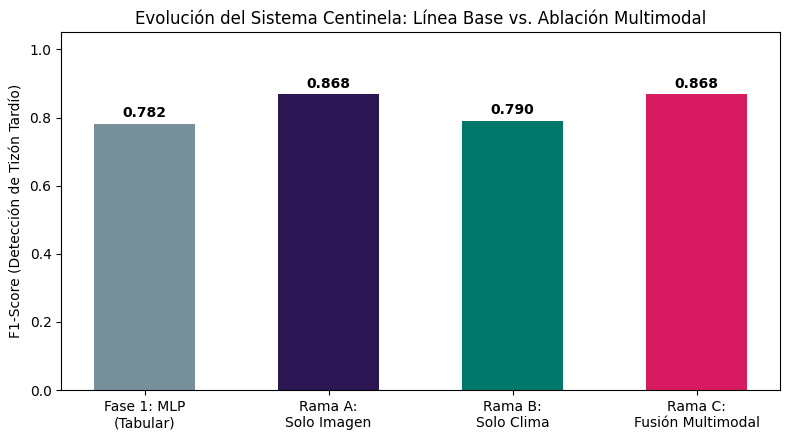

In [20]:
# 3. Cabeza de Fusión Tardía (Concatenación [z_img || z_seq] -> Dense -> Logit)
class CabezaFusionCentinela(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x)

def evaluar_modalidad_ablacion(nombre, X_tr, X_va, X_te, epocas=80, lr=1e-3):
    torch.manual_seed(42)
    mod = CabezaFusionCentinela(X_tr.shape[1]).to(device)
    n_neg, n_pos = (y_fus_tr == 0).sum(), (y_fus_tr == 1).sum()
    criterio = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optim = torch.optim.Adam(mod.parameters(), lr=lr, weight_decay=1e-3)

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32, device=device)
    y_tr_t = torch.tensor(y_fus_tr, dtype=torch.float32, device=device).view(-1, 1)
    X_va_t = torch.tensor(X_va, dtype=torch.float32, device=device)
    y_va_t = torch.tensor(y_fus_va, dtype=torch.float32, device=device).view(-1, 1)
    X_te_t = torch.tensor(X_te, dtype=torch.float32, device=device)

    mejor_val = float("inf")
    mejor_est = None
    for _ in range(epocas):
        mod.train()
        loss = criterio(mod(X_tr_t), y_tr_t)
        optim.zero_grad(); loss.backward(); optim.step()

        mod.eval()
        with torch.no_grad():
            v_loss = criterio(mod(X_va_t), y_va_t).item()
        if v_loss < mejor_val:
            mejor_val = v_loss
            mejor_est = copy.deepcopy(mod.state_dict())

    mod.load_state_dict(mejor_est)
    mod.eval()
    with torch.no_grad():
        probs = torch.sigmoid(mod(X_te_t)).cpu().numpy().ravel()

    preds = (probs >= 0.50).astype(int)
    f1  = f1_score(y_fus_te, preds)
    rec = recall_score(y_fus_te, preds)
    acc = (preds == y_fus_te).mean()
    print(f"[{nombre:22s}] Exactitud={acc:.4f} | Recall={rec:.4f} | F1-Score={f1:.4f}")
    return mod, acc, rec, f1

print("\n=== ESTUDIO DE ABLACIÓN MULTIMODAL EN PRUEBA (RAMA C) ===")
_, acc_img, rec_img, f1_img = evaluar_modalidad_ablacion("1. Solo Imagen (CNN)", Z_img_tr, Z_img_va, Z_img_te)
_, acc_seq, rec_seq, f1_seq = evaluar_modalidad_ablacion("2. Solo Serie (GRU)",  Z_seq_tr, Z_seq_va, Z_seq_te)

X_fus_tr = np.hstack([Z_img_tr, Z_seq_tr])
X_fus_va = np.hstack([Z_img_va, Z_seq_va])
X_fus_te = np.hstack([Z_img_te, Z_seq_te])
mod_fusion, acc_fus, rec_fus, f1_fus = evaluar_modalidad_ablacion("3. Fusión Tardía", X_fus_tr, X_fus_va, X_fus_te)

# Guardar pesos de la cabeza de fusión
torch.save(mod_fusion.state_dict(), "centinela_fase2_ramaC_fusion.pth")

# Gráfica comparativa para el cliente no técnico (Criterio 5)
modelos_nombres = ["Fase 1: MLP\n(Tabular)", "Rama A:\nSolo Imagen", "Rama B:\nSolo Clima", "Rama C:\nFusión Multimodal"]
f1_valores = [0.7822, f1_img, f1_seq, f1_fus] # 0.7822 es tu F1 real de Fase 1

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(modelos_nombres, f1_valores, color=["#78909c", "#2c1654", "#00796b", "#d81b60"], width=0.55)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-Score (Detección de Tizón Tardío)")
ax.set_title("Evolución del Sistema Centinela: Línea Base vs. Ablación Multimodal")
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.3f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("ablacion_multimodal_fase2.png", dpi=300)
plt.show()